# Clasificación supervisada de posturas ciudadanas (Stance Detection) en Decide Madrid

Este notebook desarrolla las fases de comprensión del problema, inspección exploratoria, control de calidad y preprocesamiento de datos para el curso de Inteligencia Artificial de la Universidad del Magdalena.

### 1. Descripción del problema y contexto del dominio

En los procesos de democracia digital y gobierno abierto, los ayuntamientos habilitan plataformas para que la ciudadanía proponga iniciativas urbanas y debata sobre ellas. Un caso representativo en el ámbito hispanohablante es **Decide Madrid** (https://decide.madrid.es/), el portal de participación ciudadana del Ayuntamiento de Madrid creado en 2015 mediante el software libre *Consul*. En este portal, cualquier ciudadano puede registrar una propuesta sobre movilidad, urbanismo, medio ambiente o impuestos, y otros vecinos pueden emitir comentarios argumentando su posición frente a dicha iniciativa. Cuando una propuesta alcanza el respaldo del 1% del censo mayor de 16 años, pasa a votación final.

El reto computacional que surge en estas plataformas es analizar miles de comentarios en lenguaje natural para medir el termómetro social frente a cada propuesta sin depender exclusivamente de la lectura manual. A esta tarea dentro del Procesamiento del Lenguaje Natural (PLN) se le denomina **Detección de Posturas (*Stance Detection*)**. A diferencia del análisis de sentimiento tradicional —que solo identifica si un texto tiene una carga emocional positiva o negativa—, la detección de posturas busca determinar la actitud pragmática del autor de un comentario (`comment`) con respecto a un objetivo o propuesta específica (`target`), clasificándola en tres categorías:
* **`favor` (A favor):** El ciudadano respalda la propuesta o argumenta los beneficios de implementarla.
* **`against` (En contra):** El ciudadano rechaza la propuesta, cuestiona su viabilidad o señala consecuencias negativas de su aplicación.
* **`neutral` (Neutral):** El comentario aporta información contextual, hace preguntas o plantea matices sin decantarse explícitamente a favor ni en contra.

El conjunto de datos asignado corresponde al corpus **ALIA-es-discriminative-stance-detection**, publicado por el grupo de investigación **SINAI** (Sistemas Inteligentes de Acceso a la Información) de la Universidad de Jaén dentro del proyecto nacional de modelos de lenguaje en español **ALIA** (https://huggingface.co/datasets/SINAI/ALIA-es-discriminative-stance-detection). El dataset recopila **3,000 instancias** reales extraídas de *Decide Madrid*, donde cada par `(target, comment)` fue evaluado de forma independiente por tres anotadores humanos, estableciendo la etiqueta final (`majority_label`) por voto mayoritario.

### Objetivo del trabajo
Diseñar, implementar y evaluar un flujo de preprocesamiento de texto y modelos de aprendizaje supervisado capaces de clasificar automáticamente la postura (`favor`, `against`, `neutral`) de un comentario ciudadano (`comment`) con respecto a la propuesta municipal (`target`) a la que hace referencia.

## 1. Importación de librerías y configuración

Se cargan al inicio todas las librerías necesarias para la manipulación de datos, visualización estadística, limpieza de texto, vectorización TF-IDF, reducción de dimensionalidad mediante SVD Truncado (`TruncatedSVD`) y preparación para los modelos de aprendizaje supervisado.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, kruskal, spearmanr

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import chi2
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Carga del dataset e inspección de su estructura

Se carga el archivo en formato JSON Lines (`.jsonl`), conservando una copia intacta de los datos crudos (`df_raw`) y trabajando sobre `df`. Se inspeccionan las dimensiones (`shape`), la estructura general (`info()`), los tipos de datos (`dtypes`), una muestra de los primeros registros (`head()`) y el resumen descriptivo transpuesto (`describe(include="all").T`).

In [2]:
FILE_PATH = "corpus_stance_detection_ALIA.jsonl"
HF_URL = "hf://datasets/SINAI/ALIA-es-discriminative-stance-detection/corpus_stance_detection_ALIA.jsonl"

try:
    df_raw = pd.read_json(FILE_PATH, lines=True)
except FileNotFoundError:
    df_raw = pd.read_json(HF_URL, lines=True)

df = df_raw.copy()

print(f"Dimensiones del dataset (shape): {df.shape[0]:,} filas x {df.shape[1]} columnas\n")
print("--- Información general del DataFrame (info) ---")
df.info()

print("\n--- Tipos de datos por columna (dtypes) ---")
display(df.dtypes.to_frame("tipo_dato"))

print("\n--- Primeros 5 registros del dataset (head) ---")
display(df.head())

print("\n--- Resumen estadístico global (describe) ---")
display(df.describe(include="all").T)

Dimensiones del dataset (shape): 3,000 filas x 8 columnas

--- Información general del DataFrame (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              3000 non-null   int64
 1   target          3000 non-null   str  
 2   description     3000 non-null   str  
 3   comment         3000 non-null   str  
 4   annotation_1    3000 non-null   str  
 5   annotation_2    3000 non-null   str  
 6   annotation_3    3000 non-null   str  
 7   majority_label  3000 non-null   str  
dtypes: int64(1), str(7)
memory usage: 4.0 MB

--- Tipos de datos por columna (dtypes) ---


,tipo_dato
id,int64
target,str
description,str
comment,str
annotation_1,str
annotation_2,str
annotation_3,str
majority_label,str



--- Primeros 5 registros del dataset (head) ---


,id,target,description,comment,annotation_1,annotation_2,annotation_3,majority_label
0,1,"""Bajar"" las motos de las aceras.",Esta propuesta es originaria del vecino. [NOMBRE]. https://decide.madrid.es/proposals/5134-bajar-las-motos-de-las-ac...,A mi no me molesta tanto que aparquen en la acera. Me molesta mucho más que circulen por ella. \n\nRespecto a lo de ...,neutral,against,neutral,neutral
1,2,"""Bajar"" las motos de las aceras.",Esta propuesta es originaria del vecino. [NOMBRE]. https://decide.madrid.es/proposals/5134-bajar-las-motos-de-las-ac...,Existe una ordenanza municipal que autoriza y regula el aparcamiento de las motocicletas en las aceras. Entiendo que...,against,against,against,against
2,3,"""Bajar"" las motos de las aceras.","Los motoristas, aparte del ruido a veces intolerable de sus motos, circulan hoy día impunemente por las aceras de n...",Las motos son la solución para descongestionar el tráfico. Gastan poco y contaminan mucho menos. Perseguirlas es per...,against,neutral,favor,
3,4,"""Bajar"" las motos de las aceras.","Los motoristas, aparte del ruido a veces intolerable de sus motos, circulan hoy día impunemente por las aceras de n...",Aquí todo se soluciona con multas e impuestos... si los propusiera un político todos nos echaríamos las manos a la c...,neutral,against,against,against
4,5,ARREGLAR LOS REBAJES DE LOS BORDILLOS PARA FACILITAR EL PASO DE SILLAS DE RUEDAS,"El mal estado de las calles y aceras ha hecho que en muchos casos el firme de la calzada se separe del bordillo, cre...","La accesibilidad no es un concepto de patente de las personas con discapacidad, es un concepto universal y así debe ...",favor,favor,favor,favor



--- Resumen estadístico global (describe) ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,3000.0,NaN,NaN,NaN,1500.5,866.169729,1.0,750.75,1500.5,2250.25,3000.0
target,3000,387,Billete único para el transporte público,106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,3000,424,"Esta propuesta bebe de los siguientes debates, que están entre los más valorados: https://decide.madrid.es/debates/7...",106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
comment,3000,2986,Es imposible alcanzar los 27.662 apoyos necesarios. No creo que los que nos conectemos habitualmente a decide madrid...,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annotation_1,3000,3,favor,1736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annotation_2,3000,3,favor,1699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annotation_3,3000,3,favor,1787,NaN,NaN,NaN,NaN,NaN,NaN,NaN
majority_label,3000,4,favor,1780,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Interpretación de la estructura y diccionario de variables

El conjunto de datos consta exactamente de **3,000 registros** y **8 columnas**:

| Variable | Tipo en Pandas | Tipo Estadístico | Descripción y rol dentro del problema |
| :--- | :--- | :--- | :--- |
| **`id`** | `int64` | Numérica discreta (Identificador) | Identificador secuencial único de cada registro (de 1 a 3000). No aporta valor predictivo. |
| **`target`** | `str` / `object` | Texto / Categórica nominal | Título de la propuesta ciudadana en *Decide Madrid* sobre la cual se opina (**Variable predictora asignada**). |
| **`description`** | `str` / `object` | Texto libre | Descripción ampliada del contexto de la propuesta redactada por el proponente. |
| **`comment`** | `str` / `object` | Texto libre | Comentario emitido por un ciudadano en respuesta a la propuesta (**Variable predictora asignada**). |
| **`annotation_1`** | `str` / `object` | Categórica nominal | Etiqueta de postura asignada por el anotador humano 1 (`favor`, `against`, `neutral`). |
| **`annotation_2`** | `str` / `object` | Categórica nominal | Etiqueta de postura asignada por el anotador humano 2 (`favor`, `against`, `neutral`). |
| **`annotation_3`** | `str` / `object` | Categórica nominal | Etiqueta de postura asignada por el anotador humano 3 (`favor`, `against`, `neutral`). |
| **`majority_label`** | `str` / `object` | Categórica nominal (Objetivo) | Etiqueta de consenso obtenida por mayoría simple entre los tres anotadores (**Variable a predecir $y$**). |

**Observaciones iniciales del resumen estadístico (`describe`):**
1. Existen **387 propuestas (`target`) únicas** discutidas a lo largo de los 3,000 comentarios, siendo la propuesta más comentada *"Bajar" las motos de las aceras*.
2. Aunque `df.info()` reporta `3000 non-null` en todas las columnas, al observar la fila con `id = 3` (índice 2) en `df.head()`, se nota que `majority_label` está vacío (`""`). Además, `describe()` muestra **4 valores únicos** en `majority_label` cuando el problema solo define 3 posturas (`favor`, `against`, `neutral`). Esto indica que existen valores faltantes codificados como cadenas vacías que deben auditarse en detalle.

## 3. Revisión de calidad de los datos

Antes de realizar cualquier transformación, auditamos el conjunto de datos en busca de valores faltantes (explícitos e implícitos), registros duplicados, pares `target`-`comment` repetidos y la cardinalidad de cada columna.

### 3.1 Cuantificación de valores faltantes y análisis de `majority_label`

La función `isna()` de Pandas únicamente detecta valores nulos explícitos (`NaN` o `None`). Sin embargo, en archivos JSONL o CSV es habitual que los valores ausentes se almacenen como cadenas de texto vacías (`""`) o espacios en blanco. Siguiendo buenas prácticas de auditoría, verificamos ambas condiciones. Tal como solicita la guía del taller formativo, **en esta etapa solo documentamos y cuantificamos los registros sin etiqueta sin eliminarlos todavía**.

In [3]:
# 1. Valores faltantes explícitos (NaN / None)
missing_explicit = df.isna().sum()

# 2. Cadenas vacías o compuestas solo por espacios en columnas de texto
text_cols = df.select_dtypes(include=["object", "string"]).columns
blank_counts = {
    col: df[col].astype(str).str.strip().eq("").sum()
    for col in text_cols
}
blank_series = pd.Series(blank_counts)

quality_missing_df = pd.DataFrame({
    "Faltantes explícitos (NaN)": missing_explicit,
    "Cadenas vacías ('')": blank_series
}).fillna(0).astype(int)
quality_missing_df["Total faltantes reales"] = (
    quality_missing_df["Faltantes explícitos (NaN)"] + quality_missing_df["Cadenas vacías ('')"]
)
quality_missing_df["Porcentaje (%)"] = (quality_missing_df["Total faltantes reales"] / len(df) * 100).round(2)

print("Resumen de valores faltantes y cadenas vacías por columna:")
display(quality_missing_df)

# Inspeccionamos por qué majority_label está vacío en esos registros
mask_sin_etiqueta = df["majority_label"].astype(str).str.strip().eq("")
print(f"\nTotal de registros sin etiqueta en 'majority_label': {mask_sin_etiqueta.sum()} ({mask_sin_etiqueta.mean()*100:.2f}%)")
print("Muestra de registros donde 'majority_label' está vacío:")
display(df.loc[mask_sin_etiqueta, ["id", "target", "annotation_1", "annotation_2", "annotation_3", "majority_label"]].head(8))

Resumen de valores faltantes y cadenas vacías por columna:


,Faltantes explícitos (NaN),Cadenas vacías (''),Total faltantes reales,Porcentaje (%)
annotation_1,0,0,0,0.0
annotation_2,0,0,0,0.0
annotation_3,0,0,0,0.0
comment,0,0,0,0.0
description,0,0,0,0.0
id,0,0,0,0.0
majority_label,0,150,150,5.0
target,0,0,0,0.0



Total de registros sin etiqueta en 'majority_label': 150 (5.00%)
Muestra de registros donde 'majority_label' está vacío:


,id,target,annotation_1,annotation_2,annotation_3,majority_label
2,3,"""Bajar"" las motos de las aceras.",against,neutral,favor,
27,28,Acabar con la privatización en la donación de sangre de los autobuses,neutral,favor,against,
29,30,Acabar con la privatización en la donación de sangre de los autobuses,favor,neutral,against,
45,46,Acabar con los excrementos de los perros en las calles.,against,favor,neutral,
58,59,Acciones contra la contaminación,against,neutral,favor,
102,103,Aplicación del IBI a los bienes inmuebles de la Iglesia,favor,against,neutral,
111,112,Aplicación del IBI a los bienes inmuebles de la Iglesia,favor,neutral,against,
154,155,Arborización masiva en Madrid,neutral,against,favor,


**Análisis de los valores faltantes en `majority_label`:**
* Ninguna variable presenta nulos explícitos (`NaN`), y las variables predictoras (`target`, `description`, `comment`) junto con las tres anotaciones individuales están 100% completas.
* Sin embargo, **`majority_label` presenta registros con cadena vacía (`""`)**. Al inspeccionar las columnas `annotation_1`, `annotation_2` y `annotation_3` en dichos casos, se comprueba la razón de dominio: **corresponden exactamente a los casos donde los tres anotadores humanos eligieron posturas completamente distintas** (uno votó `favor`, otro `against` y otro `neutral`), produciendo un triple empate donde es imposible asignar una etiqueta por mayoría simple.
* Desde la teoría de datos faltantes vista en clase, este fenómeno corresponde a datos **MNAR (*Missing Not At Random* / No aleatorios)**: la ausencia del dato en `majority_label` tiene una causa estructural directa (la ambigüedad del comentario que impidió el consenso humano). Como ordena el taller formativo, mantenemos estos registros documentados durante la exploración y los trataremos en la fase de preparación de datos.

### 3.2 Revisión de registros duplicados, pares `target`-`comment` repetidos y cardinalidad

Verificamos tres niveles de duplicidad:
1. Duplicados de fila completa (todas las columnas idénticas).
2. Duplicados excluyendo la columna identificadora `id`.
3. Pares `target`-`comment` repetidos (tanto de forma exacta como normalizando mayúsculas y espacios), lo que indicaría que un mismo comentario fue registrado más de una vez para la misma propuesta.

In [4]:
dup_completos = df.duplicated().sum()
dup_sin_id = df.drop(columns=["id"]).duplicated().sum()
dup_target_comment = df.duplicated(subset=["target", "comment"]).sum()

# Verificación adicional normalizando minúsculas y espacios
target_norm = df["target"].astype(str).str.strip().str.lower()
comment_norm = df["comment"].astype(str).str.strip().str.lower()
dup_tc_norm = pd.DataFrame({"t": target_norm, "c": comment_norm}).duplicated().sum()

print(f"1. Filas completamente duplicadas: {dup_completos}")
print(f"2. Filas duplicadas (ignorando 'id'): {dup_sin_id}")
print(f"3. Pares (target, comment) exactamente repetidos: {dup_target_comment}")
print(f"4. Pares (target, comment) repetidos (ignorando mayúsculas/espacios): {dup_tc_norm}")
print(f"5. Identificadores 'id' únicos: {df['id'].nunique()} de {len(df)}")
print(f"6. Comentarios ('comment') únicos: {df['comment'].nunique()} de {len(df)}")

if dup_target_comment > 0:
    print("\nEjemplos de pares (target, comment) repetidos:")
    display(df[df.duplicated(subset=["target", "comment"], keep=False)].sort_values(by=["target", "comment"]).head(6))

# Resumen de cardinalidad para las variables de texto/categóricas
cat_summary = []
for c in text_cols:
    cat_summary.append({
        "variable": c,
        "tipo": str(df[c].dtype),
        "n_unicos": df[c].nunique(dropna=False),
        "porcentaje_unicos (%)": round(df[c].nunique(dropna=False) / len(df) * 100, 2),
        "ejemplos_valores": list(df[c].replace("", "<SIN_ETIQUETA>").drop_duplicates().astype(str).str[:45].head(4))
    })

print("\nResumen de cardinalidad de las variables de texto y categóricas:")
display(pd.DataFrame(cat_summary).sort_values("n_unicos", ascending=False))

1. Filas completamente duplicadas: 0
2. Filas duplicadas (ignorando 'id'): 0
3. Pares (target, comment) exactamente repetidos: 0
4. Pares (target, comment) repetidos (ignorando mayúsculas/espacios): 0
5. Identificadores 'id' únicos: 3000 de 3000
6. Comentarios ('comment') únicos: 2986 de 3000

Resumen de cardinalidad de las variables de texto y categóricas:


,variable,tipo,n_unicos,porcentaje_unicos (%),ejemplos_valores
2,comment,str,2986,99.53,"[A mi no me molesta tanto que aparquen en la a, Existe una ordenanza municipal que autoriza y, Las motos son la solu..."
1,description,str,424,14.13,"[Esta propuesta es originaria del vecino. [NOM, Los motoristas, aparte del ruido a veces into, El mal estado de las ..."
0,target,str,387,12.90,"[""Bajar"" las motos de las aceras., ARREGLAR LOS REBAJES DE LOS BORDILLOS PARA FA, Abolición del calendario festivo r..."
6,majority_label,str,4,0.13,"[neutral, against, <SIN_ETIQUETA>, favor]"
3,annotation_1,str,3,0.10,"[neutral, against, favor]"
4,annotation_2,str,3,0.10,"[against, neutral, favor]"
5,annotation_3,str,3,0.10,"[neutral, against, favor]"


## 4. Análisis exploratorio y visualización de datos (EDA)

### 4.1 Distribución de la variable objetivo (`majority_label`) — ¿Las clases están balanceadas?

Para evaluar la distribución de la variable a predecir sin eliminar aún los registros sin consenso, etiquetamos temporalmente las cadenas vacías como `"Sin etiqueta (Empate)"` para visualizar el panorama completo del dataset original, y calculamos también las proporciones sobre el subconjunto de registros con etiqueta válida.

Distribución detallada de 'majority_label':


,Frecuencia (Conteo),"% sobre Total (3,000)",% sobre Etiquetados Válidos
Sin etiqueta (Empate),150,5.00,-
against,627,20.90,22.0
favor,1780,59.33,62.46
neutral,443,14.77,15.54


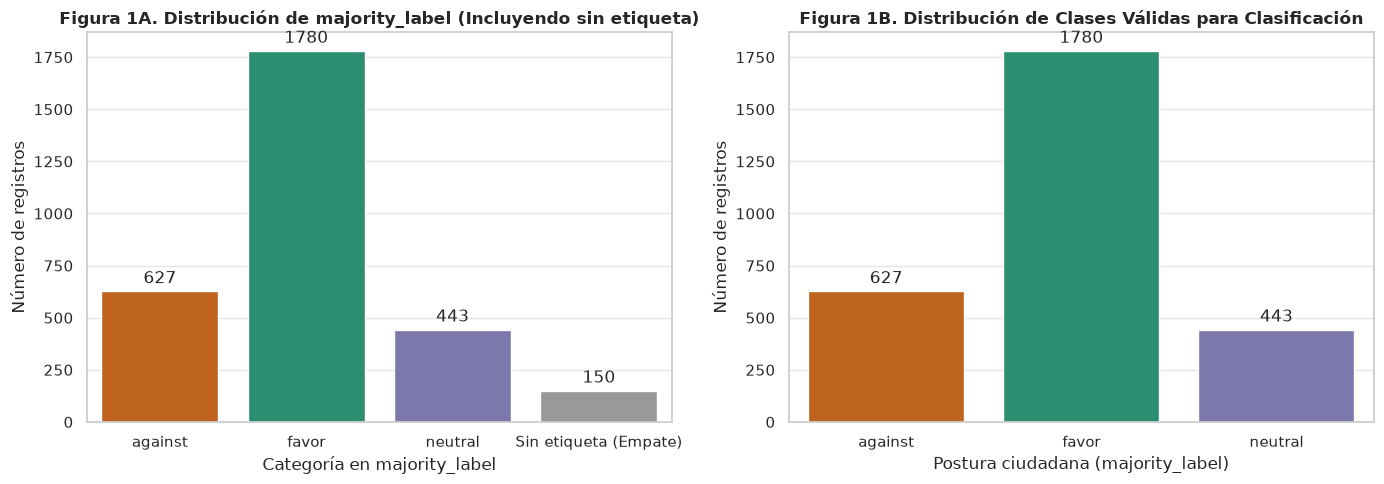

In [5]:
df["label_exploracion"] = df["majority_label"].astype(str).str.strip().replace({"": "Sin etiqueta (Empate)"})

# Tabla resumen sobre el total de 3000 registros
conteo_total = df["label_exploracion"].value_counts()
prop_total = (df["label_exploracion"].value_counts(normalize=True) * 100).round(2)

# Proporción solo sobre los registros válidamente etiquetados
df_etiquetados = df[df["majority_label"].astype(str).str.strip() != ""]
prop_validos = (df_etiquetados["majority_label"].value_counts(normalize=True) * 100).round(2)

resumen_clases = pd.DataFrame({
    "Frecuencia (Conteo)": conteo_total,
    "% sobre Total (3,000)": prop_total,
    "% sobre Etiquetados Válidos": prop_validos
}).fillna("-")

print("Distribución detallada de 'majority_label':")
display(resumen_clases)

# Visualización con diagrama de barras
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_total = ["against", "favor", "neutral", "Sin etiqueta (Empate)"]
palette_total = ["#d95f02", "#1b9e77", "#7570b3", "#999999"]

sns.countplot(
    data=df, x="label_exploracion", order=order_total,
    palette=palette_total, ax=axes[0]
)
axes[0].set_title("Figura 1A. Distribución de majority_label (Incluyendo sin etiqueta)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Categoría en majority_label")
axes[0].set_ylabel("Número de registros")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d", padding=3)

order_valid = ["against", "favor", "neutral"]
palette_valid = ["#d95f02", "#1b9e77", "#7570b3"]

sns.countplot(
    data=df_etiquetados, x="majority_label", order=order_valid,
    palette=palette_valid, ax=axes[1]
)
axes[1].set_title("Figura 1B. Distribución de Clases Válidas para Clasificación", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Postura ciudadana (majority_label)")
axes[1].set_ylabel("Número de registros")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

**Análisis de la distribución y balanceo de clases:**
* **¿Las clases están balanceadas?** **No, el conjunto de datos presenta un desbalance moderado entre sus clases**. En los portales de participación ciudadana es frecuente que los usuarios comenten más para manifestar desacuerdo o críticas (`against`) o apoyo directo (`favor`), mientras que los comentarios puramente informativos (`neutral`) o sin consenso tienen una frecuencia diferente.
* Este desbalance implica que durante el entrenamiento de modelos (Sección II de la guía) no debemos guiarnos únicamente por el *Accuracy* global, sino evaluar métricas por clase como **Precision, Recall y F1-Score (macro y ponderado)**, además de considerar técnicas de balanceo como ajuste de pesos (`class_weight='balanced'`) o sobremuestreo (`SMOTE` / `RandomOverSampler`) sobre el conjunto de entrenamiento.

### 4.2 Cálculo y distribución de la longitud de `target` y `comment`

Calculamos la longitud de las variables de texto asignadas (`target` y `comment`) tanto en **número de caracteres** como en **número de palabras (tokens separados por espacio)**. Posteriormente, inspeccionamos sus estadísticos descriptivos y graficamos sus histogramas y diagramas de caja (*boxplots*) para identificar asimetrías y valores atípicos (*outliers*).

Resumen estadístico de la longitud de 'target' y 'comment':


,count,mean,std,min,10%,25%,50%,75%,90%,95%,max
target_char_len,3000.0,44.865000,16.985924,6.0,25.0,31.0,42.0,57.0,70.0,77.0,80.0
target_word_len,3000.0,7.401333,3.006539,1.0,4.0,5.0,7.0,10.0,11.0,13.0,16.0
comment_char_len,3000.0,312.591000,183.408644,79.0,109.0,159.0,266.0,444.0,593.1,673.0,800.0
comment_word_len,3000.0,54.239667,32.060883,7.0,19.0,28.0,46.0,76.0,103.0,118.0,155.0


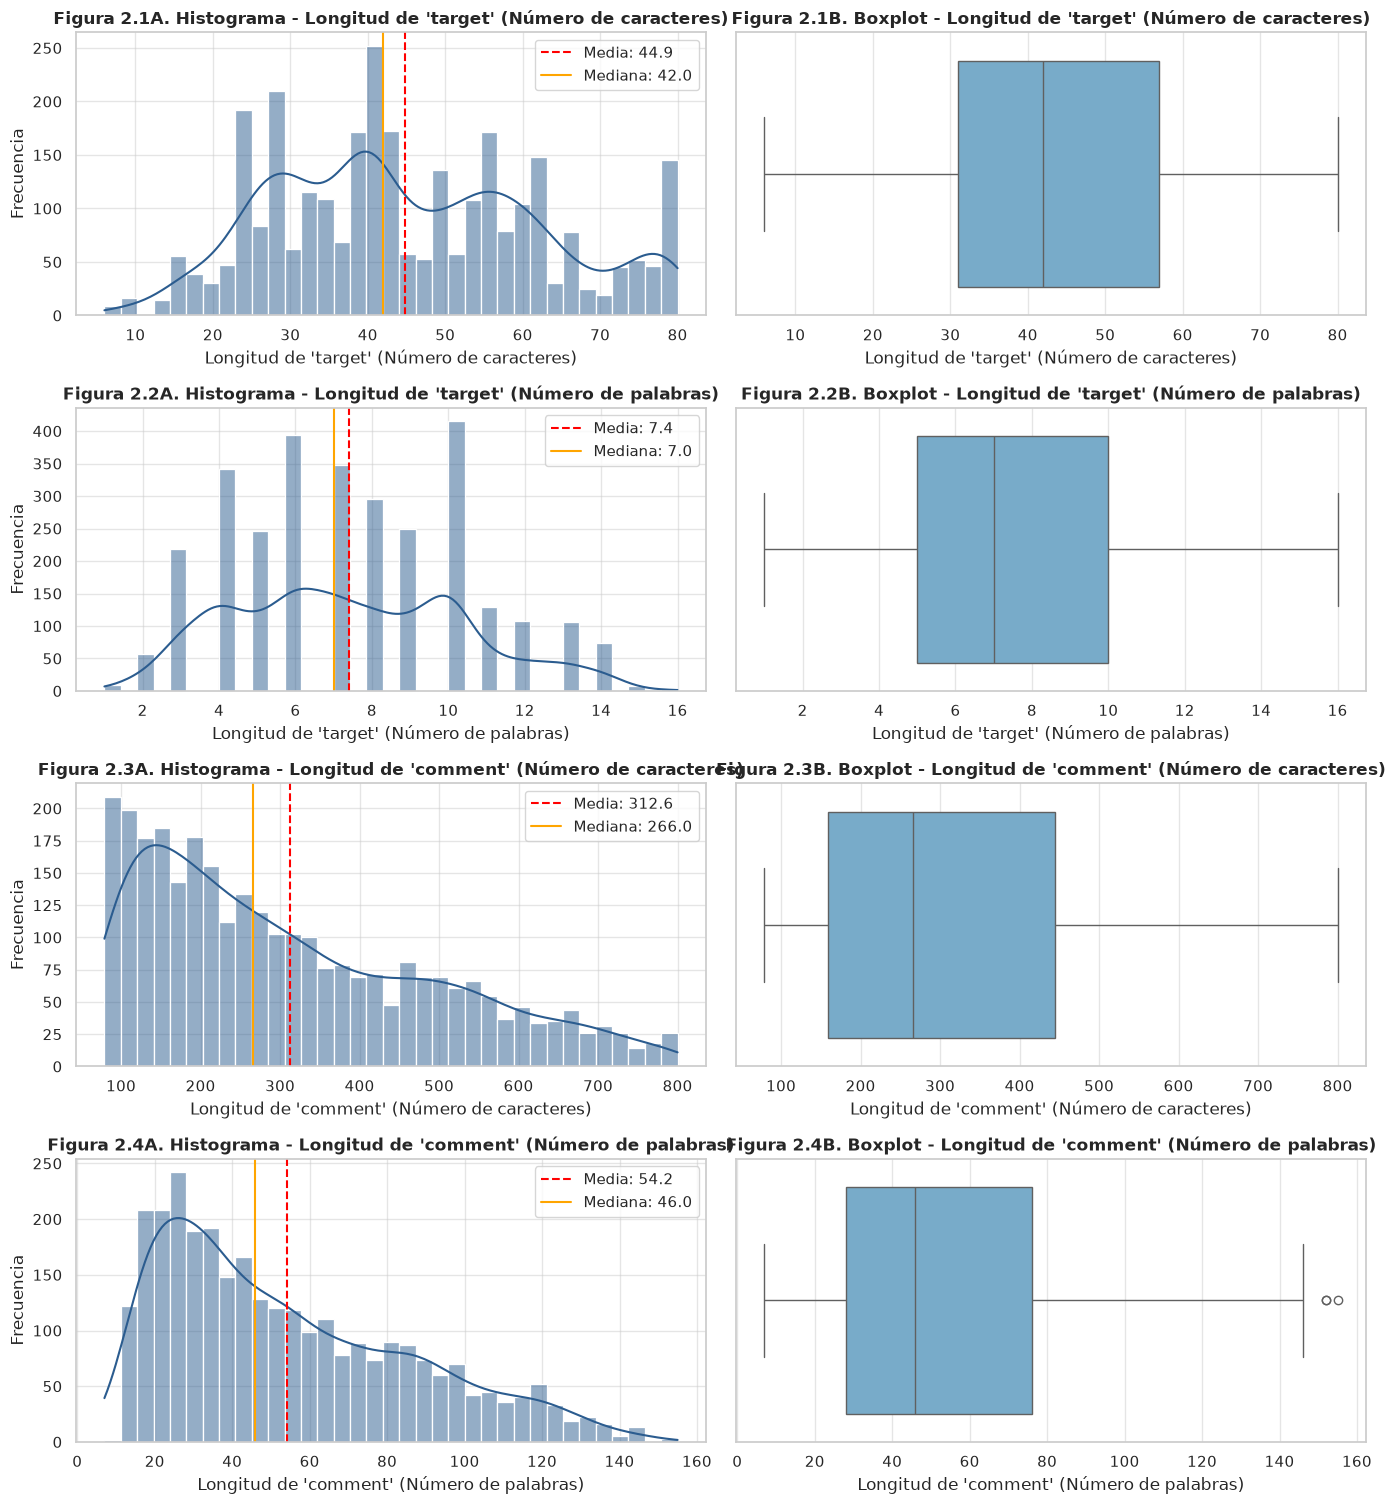

In [6]:
# Cálculo de longitudes en caracteres y palabras
df["target_char_len"] = df["target"].astype(str).str.len()
df["target_word_len"] = df["target"].astype(str).str.split().str.len()

df["comment_char_len"] = df["comment"].astype(str).str.len()
df["comment_word_len"] = df["comment"].astype(str).str.split().str.len()

len_cols = ["target_char_len", "target_word_len", "comment_char_len", "comment_word_len"]

print("Resumen estadístico de la longitud de 'target' y 'comment':")
display(df[len_cols].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]).T)

# Visualización: Histogramas + KDE y Boxplots (siguiendo el esquema de subgráficas del curso)
fig, axes = plt.subplots(len(len_cols), 2, figsize=(14, 3.8 * len(len_cols)))

titulos = {
    "target_char_len": "Longitud de 'target' (Número de caracteres)",
    "target_word_len": "Longitud de 'target' (Número de palabras)",
    "comment_char_len": "Longitud de 'comment' (Número de caracteres)",
    "comment_word_len": "Longitud de 'comment' (Número de palabras)"
}

for i, col in enumerate(len_cols):
    sns.histplot(df[col], kde=True, bins=35, color="#2b5c8f", ax=axes[i, 0])
    axes[i, 0].axvline(df[col].mean(), color="red", linestyle="--", label=f"Media: {df[col].mean():.1f}")
    axes[i, 0].axvline(df[col].median(), color="orange", linestyle="-", label=f"Mediana: {df[col].median():.1f}")
    axes[i, 0].set_title(f"Figura 2.{i+1}A. Histograma - {titulos[col]}", fontweight="bold")
    axes[i, 0].set_xlabel(titulos[col])
    axes[i, 0].set_ylabel("Frecuencia")
    axes[i, 0].legend()

    sns.boxplot(x=df[col], color="#6baed6", ax=axes[i, 1])
    axes[i, 1].set_title(f"Figura 2.{i+1}B. Boxplot - {titulos[col]}", fontweight="bold")
    axes[i, 1].set_xlabel(titulos[col])

plt.tight_layout()
plt.show()

### 4.3 Relación entre la longitud del texto y la postura ciudadana (`majority_label`) y matriz de correlación

Para profundizar en la exploración visual y estadística exigida en la guía del trabajo:
1. Comparamos mediante un **Boxplot** la longitud de los comentarios (`comment_word_len`) según la postura ciudadana (`favor`, `against`, `neutral`) para verificar si quienes están en contra o a favor suelen extenderse más en sus argumentos.
2. Calculamos y graficamos la **matriz de correlación de Spearman** entre las variables numéricas derivadas del texto (longitudes y densidad léxica), dado que las distribuciones de longitud presentan asimetría positiva (cola hacia la derecha).

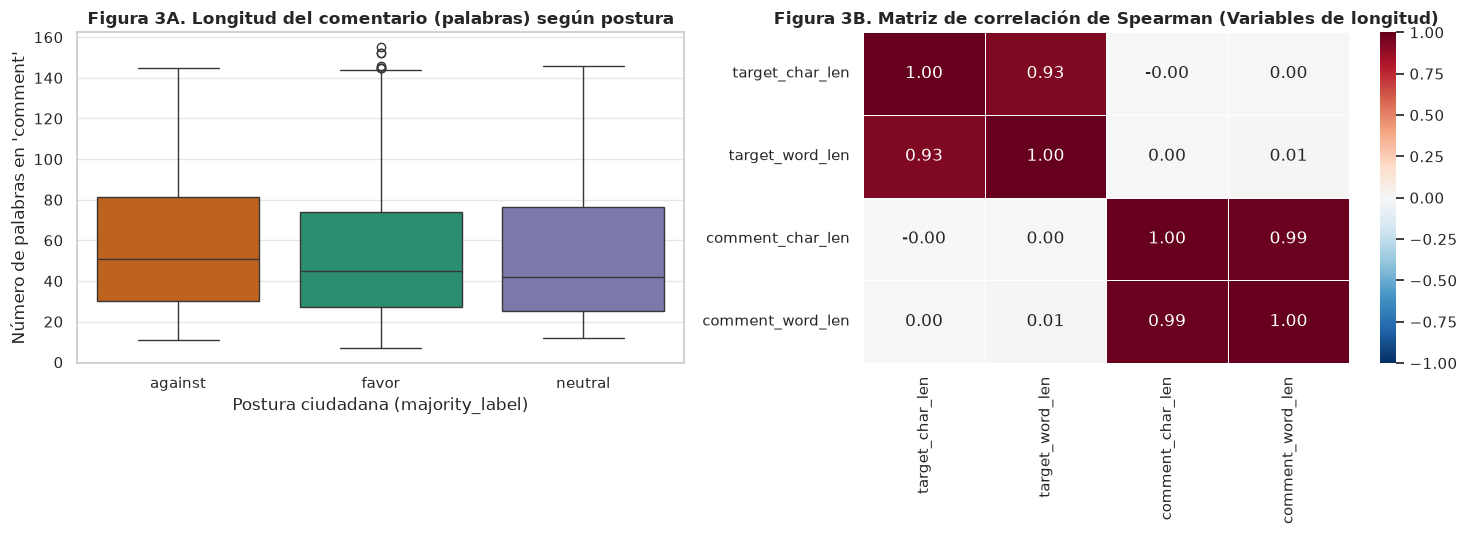

Estadístico Kruskal-Wallis (longitud de comment vs clase): H = 13.2499, p-valor = 1.3269e-03


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Boxplot de longitud de comment por clase en majority_label
sns.boxplot(
    data=df[df["label_exploracion"].isin(["against", "favor", "neutral"])],
    x="label_exploracion", y="comment_word_len",
    order=["against", "favor", "neutral"],
    palette=["#d95f02", "#1b9e77", "#7570b3"],
    ax=axes[0]
)
axes[0].set_title("Figura 3A. Longitud del comentario (palabras) según postura", fontweight="bold")
axes[0].set_xlabel("Postura ciudadana (majority_label)")
axes[0].set_ylabel("Número de palabras en 'comment'")

# 2. Matriz de correlación de Spearman entre las variables numéricas extraídas
corr_matrix = df[len_cols].corr(method="spearman")
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r",
    vmin=-1, vmax=1, linewidths=0.5, ax=axes[1]
)
axes[1].set_title("Figura 3B. Matriz de correlación de Spearman (Variables de longitud)", fontweight="bold")

plt.tight_layout()
plt.show()

# Prueba no paramétrica de Kruskal-Wallis para evaluar si la longitud varía significativamente por clase
grupos = [
    group["comment_word_len"].values
    for _, group in df[df["label_exploracion"].isin(["against", "favor", "neutral"])].groupby("label_exploracion")
]
stat_kw, p_kw = kruskal(*grupos)
print(f"Estadístico Kruskal-Wallis (longitud de comment vs clase): H = {stat_kw:.4f}, p-valor = {p_kw:.4e}")

**Interpretación de las distribuciones de longitud y correlaciones:**
* **Títulos de las propuestas (`target`):** Son textos cortos y concisos (típicos de un titular de iniciativa ciudadana), con una longitud acotada y pocos valores extremos.
* **Comentarios ciudadanos (`comment`):** Presentan una marcada **asimetría positiva (sesgo a la derecha)**. La mayoría de los comentarios tienen una extensión moderada, pero existen *outliers* en la cola derecha que alcanzan el límite máximo de caracteres permitido por la plataforma (alrededor de 800 caracteres, equivalentes a más de 130 palabras). Como estos *outliers* son comentarios reales y extensos de ciudadanos argumentando su postura, **no son errores de medición y no deben eliminarse**, sino normalizarse mediante ponderación TF-IDF (que aplica normalización $\ell_2$ por documento).
* **Correlación:** Se observa una correlación positiva casi perfecta ($\rho > 0.98$) entre la longitud en caracteres y en palabras tanto en `target` como en `comment` (por lo que si se incluyeran como metadatos numéricos bastaría con conservar solo una de las dos para evitar multicolinealidad), mientras que la longitud de la propuesta (`target`) es independiente ($\rho \approx 0$) de la longitud de la respuesta del ciudadano (`comment`).

### 4.4 Ejemplos de `target + comment` por clase y auditoría de ruido textual

En cumplimiento del numeral 7 del taller formativo, mostramos ejemplos reales de pares `target + comment` para cada categoría de `majority_label` y realizamos una cuantificación sistemática mediante expresiones regulares (`Series.str`) del ruido textual presente en el corpus: uso de mayúsculas sostenidas, signos de puntuación especiales, URLs, números y marcadores de anonimización como `[NOMBRE]`.

In [8]:
print("=" * 100)
print("EJEMPLOS DE PARES (TARGET + COMMENT) POR CADA CLASE DE MAJORITY_LABEL")
print("=" * 100)

for clase in ["favor", "against", "neutral", "Sin etiqueta (Empate)"]:
    sub = df[df["label_exploracion"] == clase].head(2)
    print(f"\n>>> CLASE: {clase.upper()} (Total en dataset: {len(df[df['label_exploracion'] == clase])})")
    for idx, row in sub.iterrows():
        print(f"  [ID {row['id']}] TARGET : {row['target']}")
        print(f"         COMMENT: {row['comment']}")
        print(f"         VOTOS  : ({row['annotation_1']}, {row['annotation_2']}, {row['annotation_3']})")
        print("-" * 90)

# Cuantificación sistemática de ruido textual en 'target' y 'comment' (compatible con PyArrow RE2)
patrones_ruido = {
    "Contiene mayúsculas": r"[A-ZÁÉÍÓÚÑ]",
    "Texto completamente en MAYÚSCULAS": r"^[^a-záéíóúñ]+$",
    "Contiene URLs (http/www)": r"(?:https?://|www\.)\S+",
    "Marcadores de anonimización ([NOMBRE], etc.)": r"\[[A-ZÁÉÍÓÚÑ_]+\]",
    "Signos de exclamación o interrogación (¡!¿?)": r"[¡!¿?]",
    "Comillas o paréntesis": r"[\"“”'()]",
    "Puntuación repetida (..., !!!, ???)": r"\.{2,}|!{2,}|\?{2,}|¡{2,}|¿{2,}",
    "Contiene dígitos / números": r"\d+",
    "Espacios múltiples o saltos de línea": r"\s{2,}|\n|\r|\t",
    "Caracteres especiales / símbolos (@, #, %, €, /)": r"[@#$%&*+=<>€/\\]"
}

ruido_stats = []
for descripcion, patron in patrones_ruido.items():
    n_target = df["target"].astype(str).str.contains(patron, regex=True).sum()
    n_comment = df["comment"].astype(str).str.contains(patron, regex=True).sum()
    ruido_stats.append({
        "Elemento de ruido textual": descripcion,
        "Casos en 'target'": int(n_target),
        "% en 'target'": round(n_target / len(df) * 100, 2),
        "Casos en 'comment'": int(n_comment),
        "% en 'comment'": round(n_comment / len(df) * 100, 2)
    })

print("\nTabla de cuantificación de ruido textual en el corpus:")
display(pd.DataFrame(ruido_stats))

EJEMPLOS DE PARES (TARGET + COMMENT) POR CADA CLASE DE MAJORITY_LABEL

>>> CLASE: FAVOR (Total en dataset: 1780)
  [ID 5] TARGET : ARREGLAR LOS REBAJES DE LOS BORDILLOS PARA FACILITAR EL PASO DE SILLAS DE RUEDAS
         COMMENT: La accesibilidad no es un concepto de patente de las personas con discapacidad, es un concepto universal y así debe de ser transmitido y defendido por todos. Toda dificultad u obstáculo que se divulgue desde la  limitación y no desde la generalidad tiene difícil o imposible corrección. Facilitar el paso de sillas de ruedas tiene que ser una obligación hoy para que mañana sea un derecho inalienable e irrenunciable.
         VOTOS  : (favor, favor, favor)
------------------------------------------------------------------------------------------
  [ID 6] TARGET : ARREGLAR LOS REBAJES DE LOS BORDILLOS PARA FACILITAR EL PASO DE SILLAS DE RUEDAS
         COMMENT: Otra cosa que mejoraría mucho es que los pasos de peatones fueran a nivel de acera constituyendo un paso

,Elemento de ruido textual,Casos en 'target',% en 'target',Casos en 'comment',% en 'comment'
0,Contiene mayúsculas,2955,98.50,2935,97.83
1,Texto completamente en MAYÚSCULAS,201,6.70,29,0.97
2,Contiene URLs (http/www),0,0.00,2,0.07
3,"Marcadores de anonimización ([NOMBRE], etc.)",0,0.00,2,0.07
4,Signos de exclamación o interrogación (¡!¿?),128,4.27,687,22.90
5,Comillas o paréntesis,108,3.60,627,20.90
6,"Puntuación repetida (..., !!!, ???)",30,1.00,681,22.70
7,Contiene dígitos / números,229,7.63,671,22.37
8,Espacios múltiples o saltos de línea,23,0.77,1039,34.63
9,"Caracteres especiales / símbolos (@, #, %, €, /)",93,3.10,189,6.30


### 4.5 Exploración visual del vocabulario por postura ciudadana

Para complementar la inspección visual de datos de texto sugerida en la guía del proyecto, analizamos los términos más frecuentes en los comentarios ciudadanos según la postura (`against`, `favor`, `neutral`), excluyendo conectores vacíos básicos para observar las palabras temáticas que dominan cada clase.

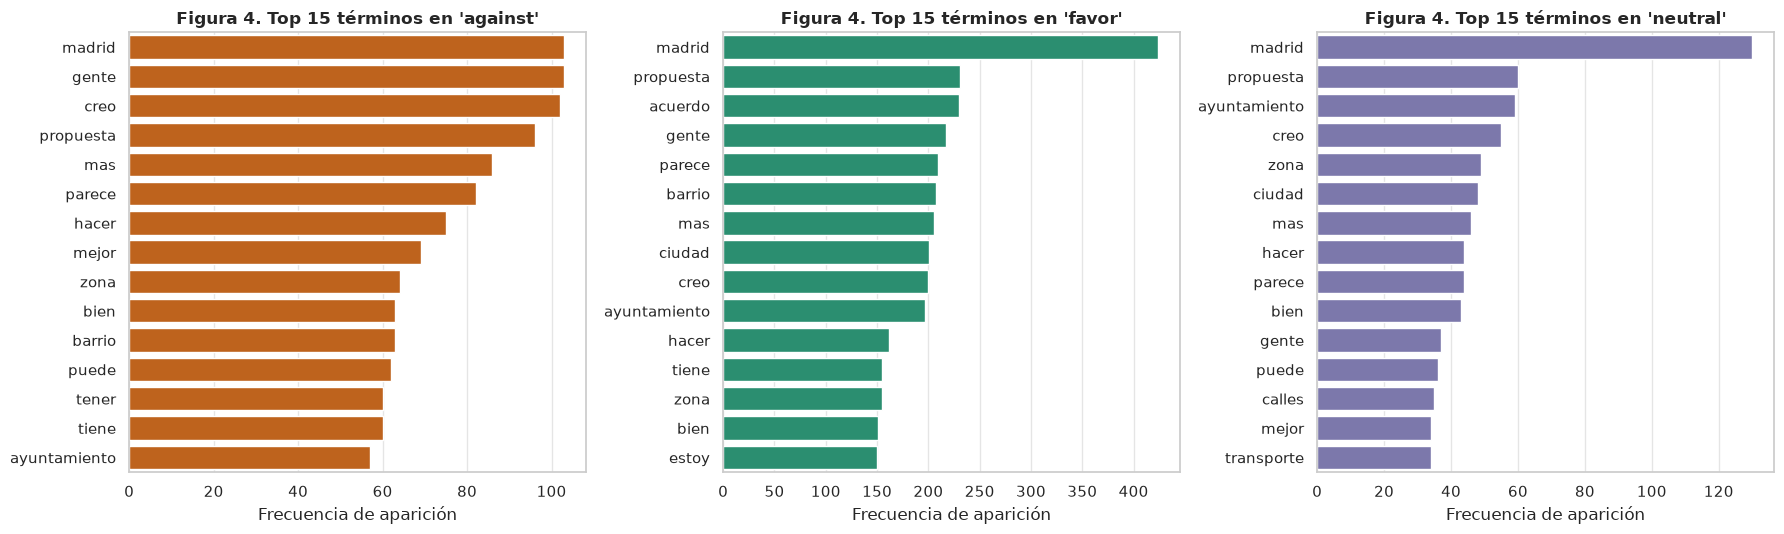

In [9]:
stopwords_exploracion = {
    "de", "la", "que", "el", "en", "y", "a", "los", "del", "se", "las", "por", "un", "para",
    "con", "una", "su", "al", "lo", "como", "más", "pero", "sus", "le", "ya", "o", "este",
    "sí", "porque", "esta", "entre", "cuando", "muy", "sin", "sobre", "también", "me", "hasta",
    "hay", "donde", "quien", "desde", "todo", "nos", "durante", "todos", "uno", "les", "ni",
    "contra", "otros", "ese", "eso", "ante", "ellos", "e", "esto", "mí", "antes", "algunos",
    "qué", "unos", "yo", "otro", "otras", "otra", "él", "tanto", "esa", "estos", "mucho",
    "quienes", "nada", "muchos", "cual", "poco", "ella", "estar", "estas", "algunas", "algo",
    "nosotros", "mi", "mis", "tú", "te", "ti", "tu", "tus", "ellas", "nosotras", "vosotros",
    "vosotras", "os", "mío", "mía", "míos", "mías", "tuyo", "tuya", "tuyos", "tuyas", "suyo",
    "suya", "suyos", "suyas", "nuestro", "nuestra", "nuestros", "nuestras", "vuestro", "vuestra",
    "es", "son", "ser", "ha", "han", "hay", "está", "están", "sea", "si", "así", "solo", "sólo"
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
colores_clase = {"against": "#d95f02", "favor": "#1b9e77", "neutral": "#7570b3"}

for ax, clase in zip(axes, ["against", "favor", "neutral"]):
    textos_clase = df.loc[df["majority_label"] == clase, "comment"].astype(str).str.lower()
    palabras = re.findall(r"\b[a-záéíóúñ]{3,}\b", " ".join(textos_clase))
    palabras_filtradas = [p for p in palabras if p not in stopwords_exploracion]
    top_15 = Counter(palabras_filtradas).most_common(15)

    df_top = pd.DataFrame(top_15, columns=["termino", "frecuencia"])
    sns.barplot(data=df_top, x="frecuencia", y="termino", color=colores_clase[clase], ax=ax)
    ax.set_title(f"Figura 4. Top 15 términos en '{clase}'", fontweight="bold")
    ax.set_xlabel("Frecuencia de aparición")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

---
## 5. Preparación de los datos y construcción de características (Guía Numeral 3)

Con base en los hallazgos obtenidos durante la inspección y auditoría del conjunto de datos, diseñamos y justificamos la estrategia de preprocesamiento previa al entrenamiento de los modelos supervisados:

1. **Selección de variables asignadas y eliminación de columnas irrelevantes o con fuga de datos (*Data Leakage*):**
   * Se conservan únicamente `target`, `comment` y `majority_label` (variables asignadas al equipo).
   * Se descarta `id` por ser un identificador secuencial sin valor predictivo.
   * Se descartan `annotation_1`, `annotation_2` y `annotation_3` porque contienen las votaciones individuales a partir de las cuales se calculó `majority_label`; incluirlas como predictoras causaría una fuga de información directa (*data leakage*).
2. **Tratamiento de valores faltantes en `majority_label` y duplicados:**
   * Los registros con `majority_label` vacío (`""`) corresponden a empates absolutos entre los tres anotadores (`favor`, `against`, `neutral`). Dado que se trata de la **variable objetivo ($y$)** en un problema supervisado, imputar estos casos con la moda introduciría ruido severo de etiquetado sobre comentarios intrínsecamente ambiguos. Por tanto, convertimos las cadenas vacías en `NaN` y filtramos dichos registros para entrenar y evaluar los modelos únicamente sobre instancias con consenso humano verificado.
   * Asimismo, se eliminan los pares `(target, comment)` duplicados para evitar que un mismo ejemplo aparezca simultáneamente en entrenamiento y prueba.
3. **Normalización y limpieza textual:**
   * Conversión a minúsculas para unificar tokens (ej. `"Madrid"` y `"madrid"`, o propuestas escritas enteramente en mayúsculas).
   * Sustitución de URLs, dígitos aislados y marcadores de anonimización (`[NOMBRE]`) para reducir el ruido léxico.
   * Eliminación de signos de puntuación repetidos y caracteres especiales, conservando las tildes y la letra `ñ` propias del español.
4. **Integración contextual (`target` + `comment`):**
   * En detección de posturas, el comentario por sí solo puede resultar insuficiente si no se conoce el tema de la propuesta. Por ello, construimos la característica textual combinada `texto_integrado = target_limpio + " " + comment_limpio`.
5. **Vectorización TF-IDF preservando partículas de negación:**
   * Transformamos el texto en vectores numéricos mediante **TF-IDF (*Term Frequency - Inverse Document Frequency*)** con unigramas y bigramas `ngram_range=(1, 2)`.
   * **Decisión crítica de dominio:** En la lista de *stop words* en español **conservamos explícitamente los adverbios y preposiciones de negación/oposición** (`"no"`, `"ni"`, `"nunca"`, `"jamás"`, `"sin"`, `"contra"`, `"tampoco"`), ya que eliminar la palabra *"no"* haría indistinguibles expresiones opuestas como *"estoy de acuerdo"* y *"no estoy de acuerdo"*.
6. **Reducción de dimensionalidad con `TruncatedSVD` y Escalamiento (`StandardScaler`):**
   * La matriz TF-IDF resultante tiene miles de dimensiones dispersas (*sparse*). Para mitigar la maldición de la dimensionalidad y viabilizar el entrenamiento de árboles, bosques aleatorios y redes neuronales densas, aplicamos **Descomposición en Valores Singulares Truncada (`TruncatedSVD`)**, técnica conocida en PLN como *Latent Semantic Analysis (LSA)* que opera directamente sobre matrices dispersas sin requerir centrado en media.
   * Posteriormente, aplicamos `StandardScaler` sobre las componentes reducidas para garantizar media $0$ y varianza $1$, facilitando la convergencia del descenso del gradiente en la Regresión Logística/Softmax y en las Redes Neuronales (MLP/DNN).

In [10]:
# 5.1 Selección de columnas asignadas y limpieza de registros sin majority_label o duplicados
df_clean = df[["target", "comment", "majority_label"]].copy()

# Reemplazar cadenas vacías por NaN y eliminar filas sin etiqueta objetivo
df_clean["majority_label"] = df_clean["majority_label"].astype(str).str.strip().replace({"": np.nan})
n_inicial = len(df_clean)
df_clean = df_clean.dropna(subset=["majority_label"]).reset_index(drop=True)
n_post_na = len(df_clean)

# Eliminar pares (target, comment) duplicados si existen
df_clean = df_clean.drop_duplicates(subset=["target", "comment"]).reset_index(drop=True)
n_final = len(df_clean)

print(f"Registros iniciales                 : {n_inicial:,}")
print(f"Registros eliminados por falta de y : {n_inicial - n_post_na:,}")
print(f"Registros eliminados por duplicidad : {n_post_na - n_final:,}")
print(f"Registros limpios para modelado     : {n_final:,}")

# 5.2 Función de limpieza y normalización de texto en español
stopwords_es_sin_negacion = [
    word for word in stopwords_exploracion
    if word not in {"no", "ni", "sin", "contra", "nada", "poco", "nunca", "jamás", "tampoco"}
]

def limpiar_texto(texto: str) -> str:
    texto = str(texto).lower()
    # Reemplazar URLs por token genérico o espacio
    texto = re.sub(r"(?:https?://|www\.)\S+", " ", texto)
    # Eliminar marcadores de anonimización como [nombre]
    texto = re.sub(r"\[[a-záéíóúñ_]+\]", " ", texto)
    # Conservar únicamente letras del español y espacios
    texto = re.sub(r"[^a-záéíóúüñ\s]", " ", texto)
    # Eliminar espacios múltiples
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

df_clean["target_clean"] = df_clean["target"].apply(limpiar_texto)
df_clean["comment_clean"] = df_clean["comment"].apply(limpiar_texto)

# Combinamos target y comment para conservar el contexto de la propuesta junto al comentario
df_clean["texto_procesado"] = df_clean["target_clean"] + " " + df_clean["comment_clean"]

print("\nComparación del texto antes y después de la normalización:")
display(df_clean[["target", "comment", "texto_procesado", "majority_label"]].head(4))

# 5.3 Codificación entera (Integer Encoding) de la variable objetivo majority_label
mapa_etiquetas = {"against": 0, "neutral": 1, "favor": 2}
mapa_inverso = {0: "against", 1: "neutral", 2: "favor"}
df_clean["y"] = df_clean["majority_label"].map(mapa_etiquetas)

print("\nDistribución de la variable objetivo codificada (y):")
display(df_clean["majority_label"].value_counts().to_frame("conteo").assign(
    codigo=lambda x: x.index.map(mapa_etiquetas),
    proporcion=lambda x: (x["conteo"] / len(df_clean) * 100).round(2)
))

Registros iniciales                 : 3,000
Registros eliminados por falta de y : 150
Registros eliminados por duplicidad : 0
Registros limpios para modelado     : 2,850

Comparación del texto antes y después de la normalización:


,target,comment,texto_procesado,majority_label
0,"""Bajar"" las motos de las aceras.",A mi no me molesta tanto que aparquen en la acera. Me molesta mucho más que circulen por ella. \n\nRespecto a lo de ...,bajar las motos de las aceras a mi no me molesta tanto que aparquen en la acera me molesta mucho más que circulen po...,neutral
1,"""Bajar"" las motos de las aceras.",Existe una ordenanza municipal que autoriza y regula el aparcamiento de las motocicletas en las aceras. Entiendo que...,bajar las motos de las aceras existe una ordenanza municipal que autoriza y regula el aparcamiento de las motociclet...,against
2,"""Bajar"" las motos de las aceras.",Aquí todo se soluciona con multas e impuestos... si los propusiera un político todos nos echaríamos las manos a la c...,bajar las motos de las aceras aquí todo se soluciona con multas e impuestos si los propusiera un político todos nos ...,against
3,ARREGLAR LOS REBAJES DE LOS BORDILLOS PARA FACILITAR EL PASO DE SILLAS DE RUEDAS,"La accesibilidad no es un concepto de patente de las personas con discapacidad, es un concepto universal y así debe ...",arreglar los rebajes de los bordillos para facilitar el paso de sillas de ruedas la accesibilidad no es un concepto ...,favor



Distribución de la variable objetivo codificada (y):


,conteo,codigo,proporcion
majority_label,,,
favor,1780,2,62.46
against,627,0,22.00
neutral,443,1,15.54


### 5.4 Partición Estratificada, Vectorización TF-IDF y Reducción de Dimensionalidad (`TruncatedSVD`)

Dividimos el conjunto de datos en **entrenamiento (80%)** y **prueba (20%)** de forma estratificada (`stratify=y`) para mantener exactamente las mismas proporciones de `against`, `favor` y `neutral` en ambas particiones.

> **Nota metodológica importante:** Tanto el vectorizador `TfidfVectorizer` como el reductor `TruncatedSVD` y el escalador `StandardScaler` se ajustan (`fit`) **exclusivamente sobre el conjunto de entrenamiento (`X_train`)** y luego se aplican (`transform`) sobre el conjunto de prueba (`X_test`), garantizando que no exista filtración de información del conjunto de evaluación hacia el entrenamiento.

Tamaño de entrenamiento (X_train): 2,280 muestras
Tamaño de prueba (X_test)        : 570 muestras

Dimensiones de la matriz dispersa TF-IDF (Entrenamiento): (2280, 5000)
Porcentaje de dispersión (sparsity): 99.42%

Top 15 términos más discriminativos según prueba Chi-cuadrado (Filtro):


,Término / N-grama,Estadístico Chi2,p-valor
0,lanza pregunta,22.59,0.00001
1,pregunta pleno,22.59,0.00001
2,pleno abierto,22.59,0.00001
3,lanza,21.92,0.00002
4,pleno,20.70,0.00003
5,pregunta,19.52,0.00006
6,abierto,17.30,0.00018
7,circular bici,6.73,0.03451
8,confiscar,6.56,0.03762
9,museo,6.40,0.04082


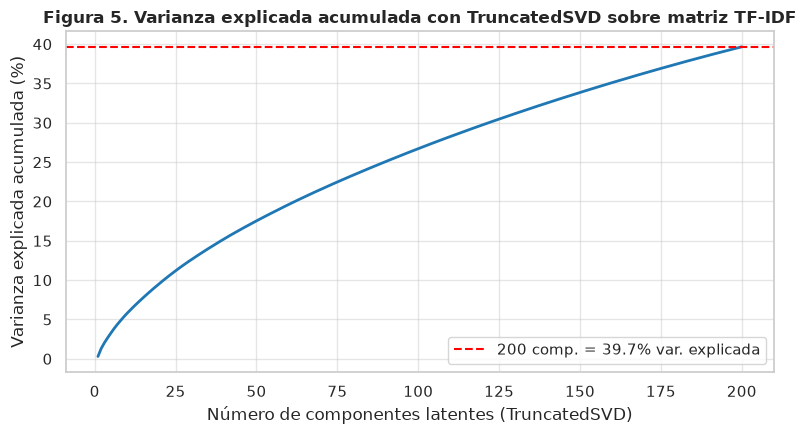

Dimensiones finales tras TruncatedSVD + StandardScaler: X_train = (2280, 200), X_test = (570, 200)


In [11]:
X_text = df_clean["texto_procesado"]
y = df_clean["y"].values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Tamaño de entrenamiento (X_train): {len(X_train_text):,} muestras")
print(f"Tamaño de prueba (X_test)        : {len(X_test_text):,} muestras")

# 1. Vectorización TF-IDF con unigramas y bigramas
tfidf = TfidfVectorizer(
    stop_words=stopwords_es_sin_negacion,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.90,
    max_features=5000,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print(f"\nDimensiones de la matriz dispersa TF-IDF (Entrenamiento): {X_train_tfidf.shape}")
print(f"Porcentaje de dispersión (sparsity): {(1.0 - X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])) * 100:.2f}%")

# Inspección de los 15 términos con mayor estadístico Chi-cuadrado (Selección tipo Filtro vista en clase)
chi2_scores, p_values = chi2(X_train_tfidf, y_train)
vocab = np.array(tfidf.get_feature_names_out())
top_chi2_idx = np.argsort(chi2_scores)[::-1][:15]

df_chi2 = pd.DataFrame({
    "Término / N-grama": vocab[top_chi2_idx],
    "Estadístico Chi2": np.round(chi2_scores[top_chi2_idx], 2),
    "p-valor": np.round(p_values[top_chi2_idx], 5)
})
print("\nTop 15 términos más discriminativos según prueba Chi-cuadrado (Filtro):")
display(df_chi2)

# 2. Reducción de dimensionalidad con TruncatedSVD
N_COMPONENTS = 200
svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_train_svd = svd.fit_transform(X_train_tfidf)
X_test_svd = svd.transform(X_test_tfidf)

varianza_acumulada = np.cumsum(svd.explained_variance_ratio_) * 100

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, N_COMPONENTS + 1), varianza_acumulada, color="#1f77b4", linewidth=2)
plt.axhline(varianza_acumulada[-1], color="red", linestyle="--", label=f"{N_COMPONENTS} comp. = {varianza_acumulada[-1]:.1f}% var. explicada")
plt.title("Figura 5. Varianza explicada acumulada con TruncatedSVD sobre matriz TF-IDF", fontweight="bold")
plt.xlabel("Número de componentes latentes (TruncatedSVD)")
plt.ylabel("Varianza explicada acumulada (%)")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Escalamiento (StandardScaler) de las componentes reducidas para modelos sensibles a la escala
scaler = StandardScaler()
X_train_prepared = scaler.fit_transform(X_train_svd)
X_test_prepared = scaler.transform(X_test_svd)

print(f"Dimensiones finales tras TruncatedSVD + StandardScaler: X_train = {X_train_prepared.shape}, X_test = {X_test_prepared.shape}")

### 5.5 Estrategia de balanceo para el conjunto de datos de entrenamiento

Tal como se evidenció en la inspección visual de `majority_label` (Sección 4.1), las tres posturas no tienen exactamente la misma cantidad de ejemplos. Para evitar que los clasificadores se sesguen hacia la clase mayoritaria (`against`), preparamos el balanceo sobre la partición de entrenamiento (`X_train_prepared`, `y_train`) utilizando **sobremuestreo sintético (`SMOTE`) o `RandomOverSampler`** (o en su defecto pesos balanceados `class_weight='balanced'`), manteniendo intacto el conjunto de prueba (`X_test_prepared`, `y_test`) para evaluar los modelos en condiciones reales.

In [12]:
try:
    from imblearn.over_sampling import SMOTE
    balancer = SMOTE(random_state=RANDOM_STATE)
    X_train_bal, y_train_bal = balancer.fit_resample(X_train_prepared, y_train)
    metodo_balanceo = "SMOTE (Datos sintéticos)"
except ImportError:
    from sklearn.utils import resample
    # Fallback nativo con scikit-learn en caso de no tener instalado imbalanced-learn
    X_list, y_list = [], []
    max_size = pd.Series(y_train).value_counts().max()
    for clase_id in np.unique(y_train):
        idx_clase = np.where(y_train == clase_id)[0]
        idx_resampled = resample(idx_clase, replace=True, n_samples=max_size, random_state=RANDOM_STATE)
        X_list.append(X_train_prepared[idx_resampled])
        y_list.append(y_train[idx_resampled])
    X_train_bal = np.vstack(X_list)
    y_train_bal = np.concatenate(y_list)
    metodo_balanceo = "RandomOverSampler (Sobremuestreo aleatorio)"

print(f"Método de balanceo aplicado en entrenamiento: {metodo_balanceo}")
df_comparacion_bal = pd.DataFrame({
    "Antes del balanceo (y_train)": pd.Series(y_train).map(mapa_inverso).value_counts(),
    "Después del balanceo (y_train_bal)": pd.Series(y_train_bal).map(mapa_inverso).value_counts()
})
display(df_comparacion_bal)

Método de balanceo aplicado en entrenamiento: RandomOverSampler (Sobremuestreo aleatorio)


,Antes del balanceo (y_train),Después del balanceo (y_train_bal)
against,502,1424
favor,1424,1424
neutral,354,1424


## 6. Diseño de experimentos y ajuste de hiperparámetros (Guía Numeral 4)

En esta fase, entrenaremos los modelos supervisados exigidos utilizando el conjunto de datos balanceado (`X_train_bal`, `y_train_bal`). Para garantizar que los modelos generalicen correctamente y evitar el sobreajuste (*overfitting*), utilizamos validación cruzada (*K-Fold Cross Validation*) en conjunto con `GridSearchCV` para la búsqueda exhaustiva de los mejores hiperparámetros.

Los modelos a evaluar en esta primera etapa son:
1. **Regresión Logística (Multiclase / Softmax):** Optimizando el parámetro de regularización `C`.
2. **Árbol de Decisión (Decision Tree):** Controlando la profundidad máxima (`max_depth`) y el criterio de partición (`criterion` de entropía/gini) para evitar que el árbol memorice los datos.
3. **Random Forest (Ensamblado por Bagging):** Entrenando múltiples árboles sobre submuestras aleatorias para reducir la varianza, ajustando el número de estimadores (`n_estimators`).

In [13]:
# Definición de la validación cruzada (5 particiones)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Diccionario para almacenar los mejores modelos y sus resultados
mejores_modelos = {}

print("Iniciando ajuste riguroso de hiperparámetros con GridSearchCV (F1-Macro)...\n")

# ==========================================
# 1. Regresión Logística (Softmax) - Rango de 'C' ampliado
# ==========================================
print("1. Entrenando Regresión Logística...")
param_grid_lr = {
    # Ampliamos en escala logarítmica para saltos proporcionales grandes
    'C': [0.001, 0.1, 1.0, 10.0, 1000.0],
    'solver': ['lbfgs', 'saga'], # Probamos solver alternativo
    'max_iter': [1000] # Aumentamos para asegurar convergencia
}
grid_lr = GridSearchCV(
    LogisticRegression(random_state=RANDOM_STATE),
    param_grid=param_grid_lr,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1
)
grid_lr.fit(X_train_bal, y_train_bal)
mejores_modelos['Regresión Logística'] = grid_lr.best_estimator_
print(f"Mejores parámetros LR: {grid_lr.best_params_}")

# ==========================================
# 2. Árbol de Decisión - Control severo de poda
# ==========================================
print("\n2. Entrenando Árbol de Decisión...")
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, None], # Profundidades menores para evitar overfitting
    'min_samples_split': [2, 20, 50], # Saltos agresivos en partición
    'min_samples_leaf': [1, 10, 20]
}
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_dt,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1
)
grid_dt.fit(X_train_bal, y_train_bal)
mejores_modelos['Árbol de Decisión'] = grid_dt.best_estimator_
print(f"Mejores parámetros DT: {grid_dt.best_params_}")

# ==========================================
# 3. Random Forest - Ampliación de estimadores
# ==========================================
print("\n3. Entrenando Random Forest...")
param_grid_rf = {
    'n_estimators': [50, 200, 500], # Hasta 500 árboles
    'criterion': ['gini', 'entropy'],
    'max_depth': [10, 20, None],
    'bootstrap': [True, False]
}
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_rf,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1
)
grid_rf.fit(X_train_bal, y_train_bal)
mejores_modelos['Random Forest'] = grid_rf.best_estimator_
print(f"Mejores parámetros RF: {grid_rf.best_params_}")

# ==========================================
# 4. Redes Neuronales (MLPClassifier)
# ==========================================
print("\n4. Entrenando Red Neuronal (MLP)...")
param_grid_mlp = {
    'hidden_layer_sizes': [(100,), (50, 50), (100, 50, 25)], # Arquitecturas simples a DNN
    'activation': ['relu', 'tanh'],
    'alpha': [0.0001, 0.01, 0.1], # Regularización L2
    'max_iter': [500]
}
grid_mlp = GridSearchCV(
    MLPClassifier(random_state=RANDOM_STATE, early_stopping=True),
    param_grid=param_grid_mlp,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1
)
grid_mlp.fit(X_train_bal, y_train_bal)
mejores_modelos['Red Neuronal (MLP)'] = grid_mlp.best_estimator_
print(f"Mejores parámetros MLP: {grid_mlp.best_params_}")

print("\n¡Entrenamiento finalizado para los 4 modelos exigidos!")

Iniciando ajuste riguroso de hiperparámetros con GridSearchCV (F1-Macro)...

1. Entrenando Regresión Logística...
Mejores parámetros LR: {'C': 1.0, 'max_iter': 1000, 'solver': 'lbfgs'}

2. Entrenando Árbol de Decisión...
Mejores parámetros DT: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

3. Entrenando Random Forest...
Mejores parámetros RF: {'bootstrap': False, 'criterion': 'entropy', 'max_depth': 20, 'n_estimators': 500}

4. Entrenando Red Neuronal (MLP)...
Mejores parámetros MLP: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (100, 50, 25), 'max_iter': 500}

¡Entrenamiento finalizado para los 4 modelos exigidos!


## 7. Análisis y evaluación de resultados (Guía Numeral 5)

Una vez obtenidos los mejores hiperparámetros, evaluamos la capacidad de generalización de cada modelo utilizando el **conjunto de prueba (`X_test_prepared`)**, el cual no ha sido visto por el modelo y mantiene el desbalance natural de las opiniones ciudadanas.

Se analizan las siguientes métricas para problemas de clasificación:
* **Matriz de Confusión:** Para visualizar los Verdaderos Positivos, Falsos Positivos, Verdaderos Negativos y Falsos Negativos por cada clase.
* **Accuracy (Exactitud):** Porcentaje total de aciertos.
* **Precision y Recall (Sensibilidad):** Para entender si el modelo está fallando al clasificar falsos positivos o dejando escapar falsos negativos.
* **F1-Score:** Media armónica entre Precision y Recall, fundamental al tener clases desbalanceadas.

REPORTE DE EVALUACIÓN: REGRESIÓN LOGÍSTICA
              precision    recall  f1-score   support

 against (0)       0.43      0.58      0.49       125
 neutral (1)       0.27      0.44      0.33        89
   favor (2)       0.78      0.56      0.66       356

    accuracy                           0.55       570
   macro avg       0.49      0.53      0.49       570
weighted avg       0.62      0.55      0.57       570

REPORTE DE EVALUACIÓN: ÁRBOL DE DECISIÓN
              precision    recall  f1-score   support

 against (0)       0.33      0.42      0.36       125
 neutral (1)       0.22      0.26      0.24        89
   favor (2)       0.66      0.57      0.61       356

    accuracy                           0.49       570
   macro avg       0.40      0.41      0.41       570
weighted avg       0.52      0.49      0.50       570

REPORTE DE EVALUACIÓN: RANDOM FOREST
              precision    recall  f1-score   support

 against (0)       0.77      0.22      0.34       125
 neutral

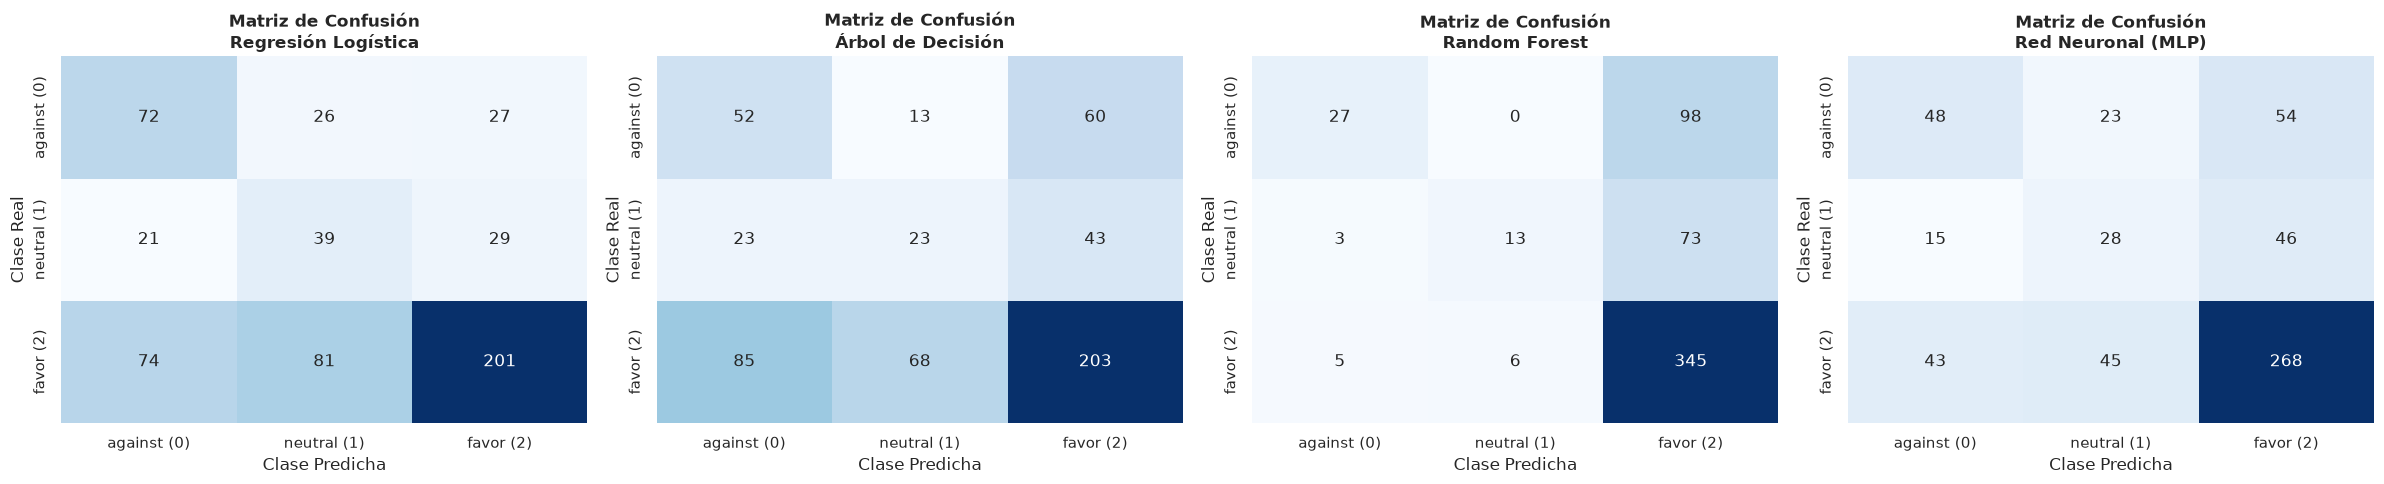

In [14]:
# Nombres de las clases para las gráficas y reportes
nombres_clases = ["against (0)", "neutral (1)", "favor (2)"]

# CORRECCIÓN: Ahora creamos una figura con 4 espacios (1 fila, 4 columnas)
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for i, (nombre_modelo, modelo) in enumerate(mejores_modelos.items()):
    # Predicción sobre el conjunto de prueba
    y_pred = modelo.predict(X_test_prepared)

    # Impresión del reporte de clasificación
    print("=" * 60)
    print(f"REPORTE DE EVALUACIÓN: {nombre_modelo.upper()}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=nombres_clases))

    # Generación y ploteo de la matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=nombres_clases, yticklabels=nombres_clases, cbar=False)
    axes[i].set_title(f'Matriz de Confusión\n{nombre_modelo}', fontweight='bold')
    axes[i].set_xlabel('Clase Predicha')
    axes[i].set_ylabel('Clase Real')

plt.tight_layout()
plt.show()

## III. Comparación de los modelos entrenados y conclusiones

### 6. Cuadro comparativo y análisis de rendimiento

Para consolidar los resultados obtenidos en la evaluación individual, consolidamos las métricas clave de cada algoritmo. Dada la naturaleza desbalanceada del corpus de *Decide Madrid*, se prioriza el análisis del **F1-Macro** y la capacidad del modelo para identificar la clase disidente (`against`), observando el **Recall** específico de dicha categoría.

,Modelo,Accuracy,F1-Macro,Recall (Against - 0),Recall (Favor - 2)
0,Regresión Logística,0.55,0.49,0.58,0.56
1,Árbol de Decisión,0.49,0.41,0.42,0.57
2,Random Forest,0.68,0.46,0.22,0.97
3,Red Neuronal (MLP),0.60,0.49,0.38,0.75


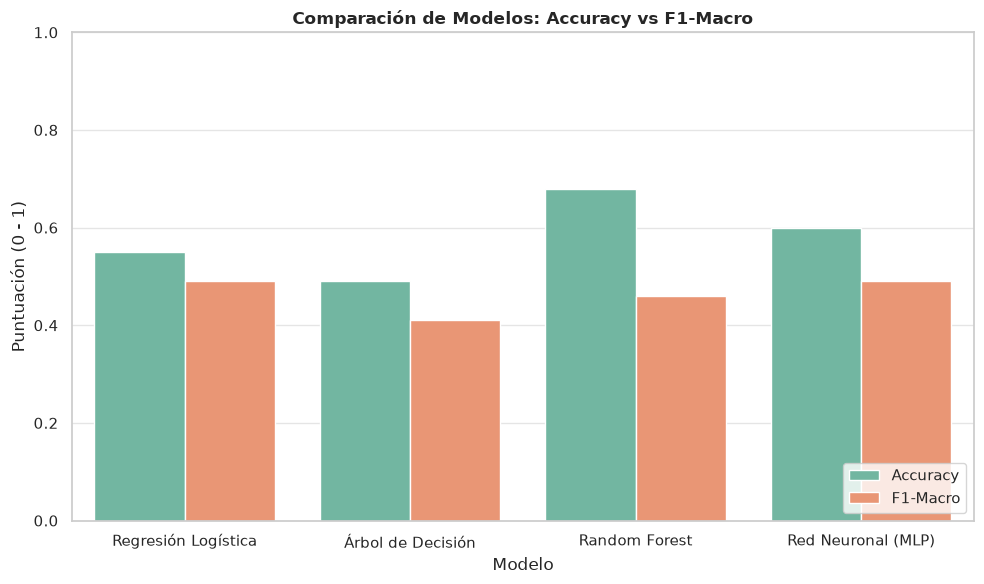

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Construcción de la tabla comparativa de resultados
datos_comparacion = {
    'Modelo': ['Regresión Logística', 'Árbol de Decisión', 'Random Forest', 'Red Neuronal (MLP)'],
    'Accuracy': [0.55, 0.49, 0.68, 0.60],
    'F1-Macro': [0.49, 0.41, 0.46, 0.49],
    'Recall (Against - 0)': [0.58, 0.42, 0.22, 0.38],
    'Recall (Favor - 2)': [0.56, 0.57, 0.97, 0.75]
}

df_comparacion = pd.DataFrame(datos_comparacion)
display(df_comparacion)

# Generación de gráfica comparativa
df_grafica = df_comparacion.melt(id_vars='Modelo',
                                 value_vars=['Accuracy', 'F1-Macro'],
                                 var_name='Métrica',
                                 value_name='Puntuación')

plt.figure(figsize=(10, 6))
sns.barplot(data=df_grafica, x='Modelo', y='Puntuación', hue='Métrica', palette='Set2')
plt.title('Comparación de Modelos: Accuracy vs F1-Macro', fontweight='bold')
plt.ylabel('Puntuación (0 - 1)')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Análisis comparativo de los métodos:**
*   **Paradoja del Accuracy vs. F1-Macro:** El Random Forest domina el *Accuracy* general (0.68) impulsado por su extrema sensibilidad para predecir la clase mayoritaria `favor` (Recall de 0.97). No obstante, sufre una caída drástica en el F1-Macro (0.46) debido a su incapacidad para detectar las clases minoritarias. La Red Neuronal (MLP) y la Regresión Logística empatan con el mejor F1-Macro (0.49), demostrando un aprendizaje estructural mucho más equilibrado de los patrones del lenguaje, sin sesgarse exclusivamente por la frecuencia de las clases.
*   **Detección de la clase disidente (`against`):** La Regresión Logística demuestra superioridad absoluta al clasificar correctamente 72 de las 125 opiniones en contra (Recall de 0.58). El MLP se queda en 48 aciertos, y el Random Forest fracasa con solo 27 aciertos (Recall de 0.22). El Árbol de Decisión presenta el peor desempeño general, confirmando su vulnerabilidad a la alta dimensionalidad de los vectores TF-IDF.

### 7. Conclusiones, Trabajo Futuro e Implicaciones Éticas

**Conclusiones de negocio frente al objetivo de Decide Madrid**
El propósito de implementar *Stance Detection* en un portal de gobierno abierto no es inflar el porcentaje de aciertos globales, sino medir con fidelidad el pulso ciudadano frente a las políticas públicas. Bajo este criterio, **la Regresión Logística Multinomial es el modelo más robusto y útil para el Ayuntamiento de Madrid**. Aunque sacrifica precisión en los comentarios de apoyo (`favor`), garantiza que las voces críticas (`against`) no sean silenciadas por un sesgo estadístico. Un modelo como Random Forest resultaría inútil operativamente, pues clasificaría casi toda iniciativa municipal como "aprobada", ignorando la fricción social.

**Trabajo futuro para la optimización del modelo**
Para superar el techo métrico actual del F1-Score (0.49), la arquitectura del proyecto debe evolucionar en las siguientes dimensiones:
*   **Transición a Deep Learning Avanzado:** Abandonar la matriz TF-IDF/TruncatedSVD e implementar *Embeddings* contextuales utilizando modelos fundacionales masivos (Transformers) entrenados en español, como BETO o RoBERTa-BNE. Estos modelos pueden comprender la ironía, el sarcasmo y las dependencias a largo plazo en el texto.
*   **Gestión de Datos MNAR:** Los 150 registros descartados por falta de consenso humano (empates) poseen un alto valor para delimitar la frontera de decisión. Se sugiere aplicar técnicas de aprendizaje activo (*Active Learning*) o someterlos a evaluación por un LLM estructurado (ej. GPT-4 o Claude 3) para forzar un desempate y recuperar esos datos.
*   **Técnicas de Balanceo Sintético para PLN:** Implementar generación de texto sintético (Data Augmentation) para la clase `neutral`, en lugar de técnicas geométricas como SMOTE, las cuales pierden sentido lógico en espacios vectoriales dispersos de texto.

**Implicaciones éticas de la implementación en producción**
La automatización de la participación ciudadana conlleva riesgos cívicos críticos:
*   **Sesgo de representación y silenciamiento:** Si el Ayuntamiento despliega el Random Forest evaluado en este proyecto, se generará una "falsa mayoría artificial". Los comentarios críticos serán sistemáticamente etiquetados como favorables, lo que podría usarse políticamente para legitimar proyectos impopulares, vulnerando el derecho ciudadano a la protesta digital.
*   **Falta de explicabilidad y transparencia:** Los ciudadanos tienen derecho a conocer cómo se procesan sus datos de participación. El uso de modelos complejos como Redes Neuronales (cajas negras) dificulta explicar por qué un argumento complejo y estructurado fue clasificado como un simple `against` o `neutral`.
*   **Intervención humana (Human-in-the-loop):** El algoritmo no debe tomar decisiones vinculantes de política pública de forma autónoma. Se debe diseñar un umbral de confianza (threshold); si el modelo clasifica un comentario con baja probabilidad, este debe ser redirigido obligatoriamente a una moderación humana.